# Exercises week 38

**FYS-STK3155/4155, fall 2026 — deadline Friday September 18 at midnight.**

## Adaptive learning rates and stochastic gradient descent

The aim this week is that you extend last week's gradient descent code with
the adaptive methods AdaGrad, RMSProp and Adam, that you understand what each
of them does to the step and why their learning rate is not the learning rate
of plain gradient descent, and that you replace the full gradient by a
minibatch gradient with epochs and a learning-rate schedule. Everything here is
reused directly in parts f) and h) of Project 1. The code developed in the
Tuesday session (`week38tuesday.ipynb`, Cases 1 and 2) is meant to be reused,
and the Monday notebook (`week38.ipynb`) contains worked examples of every
piece.

After completing these exercises you will have

* derived the bias correction of Adam and the first step of the adaptive
  methods, and shown why they are insensitive to the scale of a feature;
* your own implementation of AdaGrad, RMSProp and Adam in the same
  three-function structure as last week's gradient descent, checked against
  the closed-form solutions of OLS and Ridge;
* scanned the learning rate for each method and related the windows you find
  to $2/\lambda_{\max}$ (Section 4.5) and to what $\gamma$ means for an
  adaptive method (Sections 4.8–4.12);
* a stochastic gradient descent loop with minibatches, epochs and the
  schedule of Eq. (4.40), and studied the batch size and the schedule
  (Section 4.7);
* applied all of it to the Runge function at degree 10, the problem nothing
  converged on last week.

Reading: Chapter 4, Sections 4.7–4.13 of the book; Goodfellow et al.,
Sections 8.1–8.5.

## The data

We keep last week's function,

$$
f(x) = 2 - x + 5x^2, \qquad x \in [-2, 2],
$$

with $n = 100$ points and Gaussian noise of standard deviation $0.5$, fitted
with polynomial features of degree 2 (an easy problem, $\kappa \approx 1.3$)
and degree 5 (a hard one, $\kappa \approx 520$). As last week, standardise the
columns of the design matrix, centre $\boldsymbol{y}$ and use no intercept
column; the closed-form OLS and Ridge solutions are your reference.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def exercise_data(n=100, degree=2, noise=0.5, seed=2026):
    """Standardised polynomial design matrix (no intercept column) and centred targets."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(-2.0, 2.0, n)
    y = 2.0 - x + 5.0 * x**2 + noise * rng.standard_normal(n)
    X = np.column_stack([x**k for k in range(1, degree + 1)])
    X_norm = (X - X.mean(axis=0)) / X.std(axis=0)
    return X_norm, y - y.mean()

def closed_form(X, y, lam=0.0):
    """(X^T X + n lambda I)^-1 X^T y, the 1/n convention of Eq. (3.95)."""
    n, p = X.shape
    return np.linalg.solve(X.T @ X + n * lam * np.eye(p), X.T @ y)

def cost(theta, X, y, lam=0.0):
    """Eqs. (4.12) and (4.16)."""
    return np.sum((X @ theta - y) ** 2) / len(y) + lam * theta @ theta

def gradient(theta, X, y, lam=0.0):
    """Eqs. (4.13) and (4.17): your analytical gradient from last week (or jax.grad of cost)."""
    n = len(y)
    return (2.0 / n) * X.T @ (X @ theta - y) + 2.0 * lam * theta

def hessian_eigs(X, lam=0.0):
    n = len(X)
    return np.linalg.eigvalsh((2.0 / n) * X.T @ X + 2.0 * lam * np.eye(X.shape[1]))

X2, y2 = exercise_data(degree=2)
X5, y5 = exercise_data(degree=5)
for X in (X2, X5):
    eigs = hessian_eigs(X)
    print(f"degree {X.shape[1]}: kappa = {eigs.max() / eigs.min():.1f}, 2/lambda_max = {2 / eigs.max():.3f}")

degree 2: kappa = 1.3, 2/lambda_max = 0.894
degree 5: kappa = 520.3, 2/lambda_max = 0.354


## Exercise 1: what the adaptive methods do to the step (analytical)

The three adaptive methods replace the single learning rate $\gamma$ by a
per-coordinate step $\gamma/\sqrt{v_j}$, where $v_j$ estimates the second
moment of the gradient in coordinate $j$ (Section 4.8).

### 1a)

Unroll the RMSProp recursion of Eq. (4.47),
$\boldsymbol{v}_t = \rho\,\boldsymbol{v}_{t-1} + (1-\rho)\boldsymbol{g}_t^2$ with
$\boldsymbol{v}_0 = \boldsymbol{0}$, to obtain Eq. (4.49),
$\boldsymbol{v}_t = (1-\rho)\sum_{j=1}^{t}\rho^{\,t-j}\boldsymbol{g}_j^2$, and show
that the weights sum to $1 - \rho^t$. After how many steps has a gradient's
weight fallen below $1/e$ of its initial weight, for $\rho = 0.9$ and
$\rho = 0.99$? Compare with AdaGrad's sum, Eq. (4.42), whose weights are all
one.

### 1b)

Now Adam. Assume the gradient is stationary with $\mathbb{E}[g^2]$ constant.
Take the expectation of the unrolled second moment of Eq. (4.52) and derive
Eq. (4.53), $\mathbb{E}[v_t] = (1-\beta_2^{\,t})\,\mathbb{E}[g^2]$. Do the same
for the first moment with $\beta_1$. Explain why dividing by $1-\beta_i^t$,
Eq. (4.54), removes the bias exactly, and evaluate the correction factors at
$t = 1$, $t = 10$ and $t = 1000$ for the default $\beta_1 = 0.9$,
$\beta_2 = 0.999$.

### 1c)

Show that the first step of Adam, Eq. (4.55) at $t = 1$, is
$\Delta\theta_j = -\gamma\,\mathrm{sign}(g_{1,j})$ (up to $\epsilon$),
independent of the size of the gradient, and that the same holds for AdaGrad.
What is the first step of RMSProp, which has no bias correction, with
$\rho = 0.99$? What does this tell you about the meaning of $\gamma$ for these
methods, compared with plain gradient descent? Without bias correction, by
what factor would Adam's first step be too long?

### 1d)

Multiply one feature (one column of $\boldsymbol{X}$) by a constant $c$. Show
that the corresponding component of the gradient of the OLS cost scales by
$c$ and that the AdaGrad/RMSProp/Adam step in that coordinate is unchanged,
whereas the plain gradient descent step scales by $c$ (and the stability bound
$2/\lambda_{\max}$ moves). Why does this *not* mean that standardising the
data is unnecessary for the adaptive methods? (Hint: the Tuesday session's
rotated bowl.)

## Exercise 2: implementing AdaGrad, RMSProp and Adam

Extend last week's code with one step function that holds all five
optimisers. The template below has the update rules to fill in; keep the
gradient as an argument so that the analytical gradient and `jax.grad` are
interchangeable, as in part e) of Project 1.

In [2]:
def optimiser_step(method, theta, g, state, t, gamma, beta=0.9, rho=0.99,
                   beta1=0.9, beta2=0.999, eps=1e-8):
    """One update of theta from the gradient g at step t = 1, 2, ...; state carries the running quantities."""
    if method == "plain":                                    # Eq. (4.10)
        return theta - gamma * g, state
    if method == "momentum":                                 # Eq. (4.28)
        state["v"] = v = beta * state.get("v", 0.0) + gamma * g   # Eq. (4.28)
        return theta - v, state
    if method == "adagrad":                                  # Eqs. (4.42) and (4.45)
        state["r"] = r = state.get("r", 0.0) + g * g                           # Eq. (4.42)
        return theta - gamma * g / (np.sqrt(r) + eps), state      # Eq. (4.45)
    if method == "rmsprop":                                  # Eqs. (4.47) and (4.48)
        state["r"] = r = rho * state.get("r", 0.0) + (1.0 - rho) * g * g       # Eq. (4.47)
        return theta - gamma * g / (np.sqrt(r) + eps), state      # Eq. (4.48)
    if method == "adam":                                     # Eqs. (4.51), (4.52), (4.54), (4.55)
        state["m"] = m = beta1 * state.get("m", 0.0) + (1.0 - beta1) * g       # Eq. (4.51)
        state["r"] = r = beta2 * state.get("r", 0.0) + (1.0 - beta2) * g * g   # Eq. (4.52)
        m_hat, r_hat = m / (1.0 - beta1**t), r / (1.0 - beta2**t)               # Eqs. (4.54), (4.55)
        return theta - gamma * m_hat / (np.sqrt(r_hat) + eps), state
    raise ValueError(f"unknown method {method}")


def optimise(grad, theta0, method, gamma, num_iters=1000, tol=1e-8, **kw):
    """Full-gradient loop; returns all iterates and the number of steps taken."""
    theta, state = np.array(theta0, dtype=float), {}
    history = [theta.copy()]
    for t in range(1, num_iters + 1):
        g = grad(theta)
        theta, state = optimiser_step(method, theta, g, state, t, gamma, **kw)
        history.append(theta.copy())
        if np.linalg.norm(g) < tol:
            break
    return np.array(history), t

### 2a)

Run all five methods on the degree-2 data for OLS and for Ridge with
$\lambda = 0.01$ (remember the $n\lambda\boldsymbol{I}$ of the closed form).
Use $\gamma = 0.5$ for plain gradient descent and momentum and try
$\gamma \in \{0.01, 0.1\}$ for the adaptive methods. Do all of them converge to
the closed-form solution? Plot the distance
$\|\boldsymbol{\theta}_k - \hat{\boldsymbol{\theta}}\|$ against the iteration for
each method.

### 2b)

Repeat for the degree-5 data ($\kappa = 520$), with $\gamma = 0.9 \cdot 2/\lambda_{\max}$
for plain descent and momentum. Report the number of iterations to reach
$\|\boldsymbol{\theta}_k - \hat{\boldsymbol{\theta}}\| < 10^{-6}$ for each method,
and identify the method that does not get there at a constant $\gamma$.
Explain why, using your result from exercise 1c).

### 2c)

Check one method against a library implementation: for the degree-2 OLS
problem, run `optax.adam` (or `torch.optim.Adam`, or any other) with the same
$\gamma$, $\beta_1$, $\beta_2$ and $\epsilon$ from the same starting point, and
compare the first ten iterates with your own. They should agree to rounding.
If they do not, the usual suspects are the bias correction and the placement
of $\epsilon$ (inside or outside the square root).

Kappa:  1.2687690135310867 gamma_star:  0.5000000000000001 gamma_max:  0.8940827642128962
Kappa:  520.3442674566463 gamma_star:  0.35313225872240533 gamma_max:  0.35381090991702396


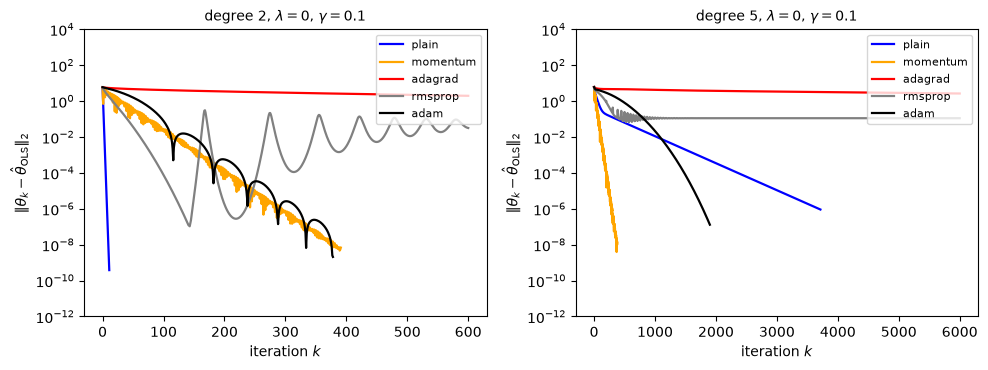

Kappa:  1.2687690135310867 gamma_star:  0.5000000000000001 gamma_max:  0.8940827642128962
Kappa:  520.3442674566463 gamma_star:  0.35313225872240533 gamma_max:  0.35381090991702396


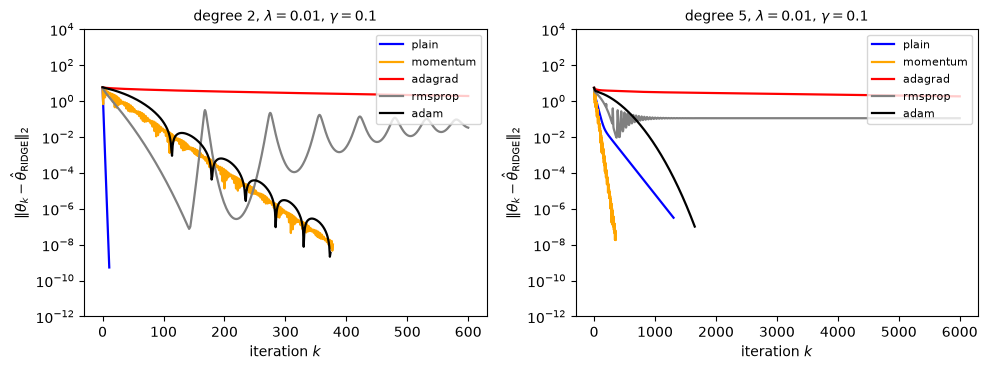

In [3]:
# Your code for exercise 2 here
from matplotlib.pyplot import axes


lmbda = 0
g = 0.5

methods = ("plain", "momentum", "adagrad", "rmsprop", "adam")
colors = ["blue", "orange", "red", "grey", "black"]

def fig_gd_convergence(lmbda=0):
    fig, axes = plt.subplots(1,2,figsize=(10, 3.8))
    for ax, degree, iters in zip(axes, (2,5), (600,6000)):
        X, y = exercise_data(degree=degree)
        theta_cf = closed_form(X, y,lam=lmbda)

        grad = lambda th: gradient(th, X, y, lam=lmbda)

        eigs = hessian_eigs(X)
        lmax, lmin = eigs.max(), eigs.min()
        gamma_star, gamma_max = 2.0 / (lmax + lmin), 2.0 / lmax
        gammas = [0.1 * gamma_max, 0.5 * gamma_max, gamma_star, 0.99 * gamma_max, 1.02 * gamma_max]
        print("Kappa: ", lmax / lmin, "gamma_star: ", gamma_star, "gamma_max: ", gamma_max)
        
        for method, col in zip(methods, colors):
            if method == "plain" or method == "momentum": 
                if degree == 5: g = 0.9*gamma_max
                else:
                    g = 0.5
            else:
                g = 0.1
            
            hist, _ = optimise(grad, np.zeros(degree), method, g, num_iters=iters)
            dist = np.linalg.norm(hist - theta_cf, axis=1)
            ax.semilogy(dist, color=col, label=method, lw=1.6)

        ax.set_title(rf"degree {degree}, $\lambda={lmbda}$, $\gamma={g}$", fontsize=10)
        ax.set_xlabel("iteration $k$")
        ax.set_ylim(1e-12, 1e4)
        ax.legend(fontsize=8, loc="upper right")
        if lmbda == 0:
            ax.set_ylabel(r"$\|{\theta}_k-\hat{{\theta}}_{\mathrm{OLS}}\|_2$")
        else:
            ax.set_ylabel(r"$\|{\theta}_k-\hat{{\theta}}_{\mathrm{RIDGE}}\|_2$")
    fig.tight_layout()
    plt.show()

with np.errstate(all="ignore"):

    fig_gd_convergence(lmbda=0)
    fig_gd_convergence(lmbda=0.01)





In [4]:
# 2c

X_t = torch.tensor(X2, dtype=torch.float64)
y_t = torch.tensor(y2, dtype=torch.float64)

gamma = 0.1
beta1, beta2, eps = 0.9, 0.999, 1e-8

# Our implementation
history, _ = optimise(lambda th: gradient(th, X2, y2), np.zeros(X2.shape[1]),
                     "adam", gamma=gamma, num_iters=10, beta1=beta1, beta2=beta2, eps=eps)
history = np.asarray(history)

# PyTorch implementation
p = X2.shape[1]
theta = torch.zeros(p, dtype=torch.float64, requires_grad=True)
opt = torch.optim.Adam([theta], lr=gamma, betas=(beta1, beta2), eps=eps)
torch_history = [theta.detach().numpy().copy()]
for _ in range(10):
    opt.zero_grad()
    loss = torch.mean((X_t @ theta - y_t) ** 2)
    loss.backward()
    opt.step()
    torch_history.append(theta.detach().numpy().copy())
torch_history = np.asarray(torch_history)

print('max abs difference over first 11 iterates =', np.max(np.abs(history - torch_history)))
print('our Adam history (first 5):\n', history[:5])
print('torch Adam history (first 5):\n', torch_history[:5])
print('\nAllclose?', np.allclose(history, torch_history, rtol=1e-12, atol=1e-12))

max abs difference over first 11 iterates = 2.220446049250313e-16
our Adam history (first 5):
 [[ 0.          0.        ]
 [-0.1         0.1       ]
 [-0.19849772  0.19995656]
 [-0.29372033  0.29983976]
 [-0.38306731  0.39961887]]
torch Adam history (first 5):
 [[ 0.          0.        ]
 [-0.1         0.1       ]
 [-0.19849772  0.19995656]
 [-0.29372033  0.29983976]
 [-0.38306731  0.39961887]]

Allclose? True


## Exercise 3: the learning rate means something different to each method

### 3a)

For the degree-5 OLS problem, scan $\gamma$ over a logarithmic grid from
$10^{-3}$ to $1$ (about fifteen values) for each of the five methods, and
record the number of iterations to $\|\boldsymbol{\theta}_k - \hat{\boldsymbol{\theta}}\| < 10^{-6}$
(or "did not converge" within 20 000 iterations). Plot iterations against
$\gamma$ for all methods in one figure, on logarithmic axes.

### 3b)

Discuss the figure: where does each method's window of usable $\gamma$ start
and end, and how do the edges relate to $2/\lambda_{\max}$ (plain descent),
$2(1+\beta)/\lambda_{\max}$ (momentum), and to the fact that the adaptive
methods take steps of length at most $\gamma$ per coordinate? Which method is
the least sensitive to $\gamma$, and is it also the fastest at its best
$\gamma$?

### 3c)

Book Table 4.1 and Figure 4.7 compare the five methods at three learning
rates on a problem with $\kappa = 12$ and find that the ranking reverses
between $\gamma = 0.01$ and $\gamma = 0.5$. Reproduce this behaviour on your
degree-2 data (where $\kappa = 1.3$): which method is best at each $\gamma$, and
what is the lesson for how optimisers should be compared in Project 1?

gamma grid: [0.001  0.0016 0.0025 0.004  0.0063 0.01   0.0158 0.0251 0.0398 0.0631
 0.1    0.1585 0.2512 0.3981 0.631  1.    ]
plain   : usable gamma from 0.0158 to 0.2512 ; best 1200 iterations at gamma = 0.251
momentum: usable gamma from 0.0016 to 0.6310 ; best 140 iterations at gamma = 0.398
adagrad : usable gamma from 0.2512 to 1.0000 ; best 1700 iterations at gamma = 1.000
rmsprop : never reaches 1e-6 
adam    : usable gamma from 0.0010 to 1.0000 ; best 240 iterations at gamma = 0.631
degree 5: kappa = 520.3, 2/lambda_max = 0.354


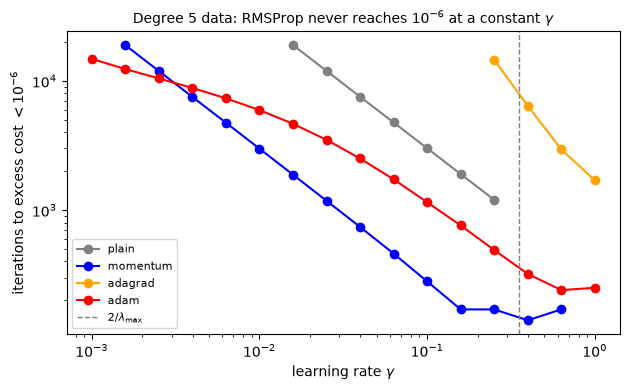

Answer: The least sensitive method is Adam, which converges for a wide range of learning rates and has a shallower slope on the figure. Momentum is faster than Adam at their best gammas.
gamma grid: [0.001  0.0016 0.0025 0.004  0.0063 0.01   0.0158 0.0251 0.0398 0.0631
 0.1    0.1585 0.2512 0.3981 0.631  1.    ]
plain   : usable gamma from 0.0010 to 0.6310 ; best 10 iterations at gamma = 0.398
momentum: usable gamma from 0.0010 to 1.0000 ; best 150 iterations at gamma = 0.100
adagrad : usable gamma from 0.0631 to 1.0000 ; best 100 iterations at gamma = 1.000
rmsprop : usable gamma from 0.0010 to 1.0000 ; best 10 iterations at gamma = 0.398
adam    : usable gamma from 0.0010 to 1.0000 ; best 120 iterations at gamma = 0.251
degree 2: kappa = 1.3, 2/lambda_max = 0.894


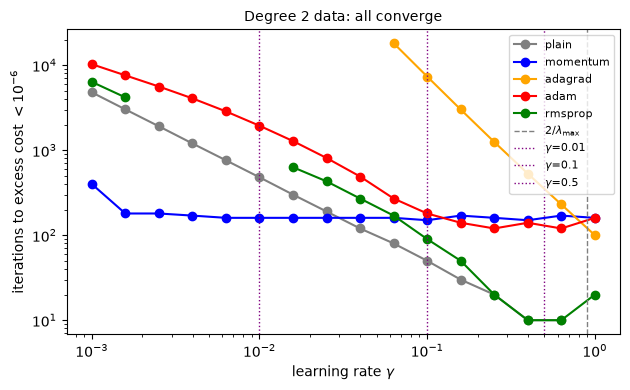

Answer: For degree 2 data: At gamma = 0.01, the momentum converges fastest, followed by plain and Adam. The other two methods do not converge at this gamma. At gamma = 0.1, the plain method converges fastest, followed by RMSprop and momentum/Adam. At gamma = 0.5, the plain method diverges, while the other methods converge with RMSprop being the fastest.


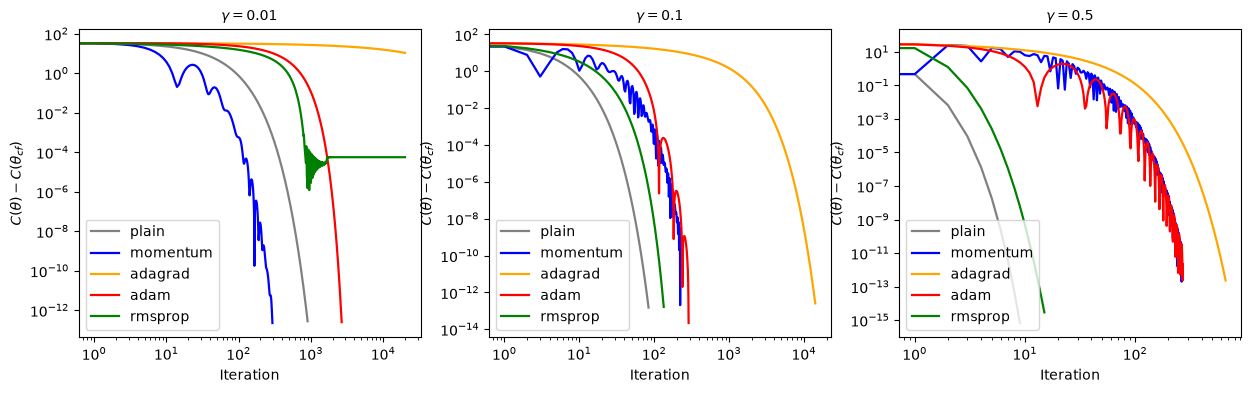

In [5]:
# Your code for exercise 3 here

# 3a) Degree 5 data:
theta5 = closed_form(X5, y5)
c5 = cost(theta5, X5, y5)
grad5 = lambda th: gradient(th, X5, y5)
gammas = np.geomspace(1e-3, 1.0, 16)
np.seterr(over="ignore", invalid="ignore")   # diverging runs overflow; that is the answer, not an error
print("gamma grid:", np.round(gammas, 4))
scan = {}
for method in ("plain", "momentum", "adagrad", "rmsprop", "adam"):
    its = []
    for g in gammas:
        path,_ = optimise(grad5, np.zeros(5), method, g, num_iters=20000)
        
        e = np.array([cost(p, X5, y5) - c5 for p in path[::10]])

        its.append(int(np.argmax(e < 1e-6)) * 10 if (e < 1e-6).any() else None)
    scan[method] = its
    ok = [(gammas[i], its[i]) for i in range(len(its)) if its[i] is not None]
    best = min(ok, key=lambda t: t[1]) if ok else None
    print(f"{method:8s}: usable gamma from {ok[0][0]:.4f} to {ok[-1][0]:.4f}" if ok else f"{method:8s}: never reaches 1e-6",
          f"; best {best[1]} iterations at gamma = {best[0]:.3f}" if best else "")

eigs5 = hessian_eigs(X5)
print(f"degree 5: kappa = {eigs5.max() / eigs5.min():.1f}, 2/lambda_max = {2 / eigs5.max():.3f}")
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for method, col in (("plain", "gray"), ("momentum", "blue"), ("adagrad", "orange"), ("adam", "red")):
    its = np.array([np.nan if k is None else k for k in scan[method]])
    ax.loglog(gammas, its, "o-", color=col, label=method)
ax.set_xlabel(r"learning rate $\gamma$"); ax.set_ylabel(r"iterations to excess cost $<10^{-6}$")
ax.axvline(2 / eigs5.max(), color="gray", ls="--", lw=1, label=r"$2/\lambda_{\max}$")

ax.set_title("Degree 5 data: RMSProp never reaches $10^{-6}$ at a constant $\\gamma$", fontsize=10)
ax.legend(fontsize=8); fig.tight_layout()
plt.show()

#3b)
print("Answer: The least sensitive method is Adam, which converges for a wide range of learning rates and has a shallower slope on the figure. Momentum is faster than Adam at their best gammas.")





# 3c) Degree 2 data:

theta2 = closed_form(X2, y2)
c2 = cost(theta2, X2, y2)
grad2 = lambda th: gradient(th, X2, y2)
gammas = np.geomspace(1e-3, 1.0, 16)
np.seterr(over="ignore", invalid="ignore")   # diverging runs overflow; that is the answer, not an error
print("gamma grid:", np.round(gammas, 4))
scan = {}
for method in ("plain", "momentum", "adagrad", "rmsprop", "adam"):
    its = []
    for g in gammas:
        path,_ = optimise(grad2, np.zeros(2), method, g, num_iters=20000)
        
        e = np.array([cost(p, X2, y2) - c2 for p in path[::10]])

        its.append(int(np.argmax(e < 1e-6)) * 10 if (e < 1e-6).any() else None)
    scan[method] = its
    ok = [(gammas[i], its[i]) for i in range(len(its)) if its[i] is not None]
    best = min(ok, key=lambda t: t[1]) if ok else None
    print(f"{method:8s}: usable gamma from {ok[0][0]:.4f} to {ok[-1][0]:.4f}" if ok else f"{method:8s}: never reaches 1e-6",
          f"; best {best[1]} iterations at gamma = {best[0]:.3f}" if best else "")

eigs2 = hessian_eigs(X2)
print(f"degree 2: kappa = {eigs2.max() / eigs2.min():.1f}, 2/lambda_max = {2 / eigs2.max():.3f}")
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for method, col in (("plain", "gray"), ("momentum", "blue"), ("adagrad", "orange"), ("adam", "red"), ("rmsprop", "green")):
    its = np.array([np.nan if k is None else k for k in scan[method]])
    ax.loglog(gammas, its, "o-", color=col, label=method)
ax.set_xlabel(r"learning rate $\gamma$"); ax.set_ylabel(r"iterations to excess cost $<10^{-6}$")
ax.axvline(2 / eigs2.max(), color="gray", ls="--", lw=1, label=r"$2/\lambda_{\max}$")
ax.axvline(0.01, color="purple", ls=":", lw=1, label=r"$\gamma$=0.01")
ax.axvline(0.1, color="purple", ls=":", lw=1, label=r"$\gamma$=0.1")
ax.axvline(0.5, color="purple", ls=":", lw=1, label=r"$\gamma$=0.5")

ax.set_title("Degree 2 data: all converge", fontsize=10)
ax.legend(fontsize=8); fig.tight_layout()
plt.show()

print("Answer: For degree 2 data: At gamma = 0.01, the momentum converges fastest, followed by plain and Adam. The other two methods do not converge at this gamma. At gamma = 0.1, the plain method converges fastest, followed by RMSprop and momentum/Adam. At gamma = 0.5, the plain method diverges, while the other methods converge with RMSprop being the fastest.")

scan = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, g in zip(axes, (0.01, 0.1, 0.5)):
    for method, col in (("plain", "gray"), ("momentum", "blue"), ("adagrad", "orange"), ("adam", "red"), ("rmsprop", "green")):

        path,iters = optimise(grad2, np.zeros(2), method, g, num_iters=20000,tol=1e-6)        
        e = np.array([cost(p, X2, y2) - c2 for p in path[::1]])
        ax.loglog(np.arange(iters+1),e,color=col,label=method, lw=1.6)

    ax.legend()
    ax.set_title(rf"$\gamma={g}$", fontsize=10)
    ax.set_xlabel("Iteration")
    ax.set_ylabel(r"$C(\theta)-C(\theta_{cf})$")
plt.show()

## Exercise 4: stochastic gradient descent

Replace the full gradient by a minibatch gradient, Eq. (4.33), inside an
epoch loop. Reshuffle the data every epoch and split the shuffled indices into
minibatches of size $M$; the update of Eq. (4.34) is one call to your
`optimiser_step`, so every optimiser of exercise 2 works with minibatches
unchanged.

In [6]:
def make_batches(n, batch_size, rng):
    """Shuffle the indices and split them into minibatches."""
    idx = rng.permutation(n)
    return [idx[i:i + batch_size] for i in range(0, n, batch_size)]

def step_length(t, t0, t1):
    """The schedule of Eq. (4.40)."""
    return t0 / (t + t1)

def sgd(X, y, method="plain", n_epochs=50, batch_size=5, gamma=0.1, schedule=None, lam=0.0, seed=2026, **kw):
    """Minibatch SGD, Eq. (4.34), with any optimiser. schedule=(t0, t1) replaces gamma by Eq. (4.40).
    Returns the iterate after every epoch."""
    rng = np.random.default_rng(seed)
    n, p = X.shape
    theta, state, t = np.zeros(p), {}, 0
    history = [theta.copy()]
    for epoch in range(n_epochs):
        for batch in make_batches(n, batch_size, rng):
            t += 1
            g = gradient(theta, X[batch], y[batch], lam)                                   # the gradient of the cost on this minibatch
            gamma_t = gamma if schedule is None else step_length(t, *schedule)                             # constant, or the schedule
            theta, state = optimiser_step(method, theta, g, state, t, gamma_t, **kw)
        history.append(theta.copy())
    return np.array(history)

### 4a)

At a fixed point $\boldsymbol{\theta} = (0, 3)$ of the degree-2 problem,
compute the gradient on many random minibatches of size $M = 1, 5, 25$ and
compare their mean and their spread (standard deviation over batches) with the
full gradient. Verify numerically that the spread falls as $1/\sqrt{M}$, and say
in one sentence what this means for the trade-off between batch size and cost
per step.

### 4b)

Run plain SGD with $M = 5$ on the degree-2 data for 100 epochs at
$\gamma = 0.1$ and at $\gamma = 0.02$, and plot the distance to the closed-form
solution against the number of *single-point gradient evaluations* (epochs
times $n$) together with full-batch gradient descent at $\gamma = 0.5$. Which
method is ahead early, which is ahead late, and does SGD with a constant
learning rate converge at all? Relate the size of the plateau to $\gamma$.

### 4c)

Now the schedule of Eq. (4.40). With $(t_0, t_1) = (1, 10)$ the initial
learning rate is $0.1$. Add this run to the plot of 4b). Then move to the
degree-5 data and run the same schedule: what happens? Find a pair $(t_0, t_1)$
with the same initial learning rate that works there, and explain your choice
in terms of the Robbins–Monro conditions $\sum_t \gamma_t = \infty$,
$\sum_t \gamma_t^2 < \infty$.

### 4d)

Study the batch size on the degree-5 data at $\gamma = 0.1$: $M \in \{1, 5, 20, 100\}$
for 100 epochs. One of these runs diverges although $\gamma$ is below
$2/\lambda_{\max}$ of the full Hessian. Which Hessian is relevant for a single
minibatch step, and what is its largest eigenvalue for $M = 1$? (For a single
point it is $2\|\boldsymbol{x}_i\|^2$.)

### 4e)

Combine SGD with Adam on the degree-5 data ($M = 5$, $\gamma \in \{0.01, 0.05\}$,
100 epochs) and compare with plain SGD and with momentum. Which combination
comes closest to the closed-form solution, and which one fails? This is the
setting of Project 1, part h).

full gradient: [ 1.47833066 -5.45421202]
M =  1: mean [ 1.478 -5.454], spread 8.477
The spread falls with: N/A
M =  5: mean [ 1.478 -5.454], spread 3.697
The spread falls with: 0.436 and 1/2.236=0.447
M = 25: mean [ 1.478 -5.454], spread 1.544
The spread falls with: 0.182 and 1/5.000=0.200
M = 50: mean [ 1.478 -5.454], spread 0.742
The spread falls with: 0.087 and 1/7.071=0.141
Answer: The mean does not change, but the spread decreases with increasing batch size. The mean is close to the full gradient. The spread falls as 1/sqrt(M), which means the tradeoff is that larger batch sizes give more accurate gradients, but they also require more computation. One therefore has to choose between accuracy and computational cost, and this is often a compromise.
M = 5, gamma = 0.1: distance after 1 / 10 / 100 epochs 8.7e-02 / 6.5e-02 / 4.8e-02, min over the last 50 epochs 1.3e-02
M = 5, gamma = 0.02: distance after 1 / 10 / 100 epochs 2.7e+00 / 1.2e-03 / 7.0e-03, min over the last 50 epochs 2.7e-

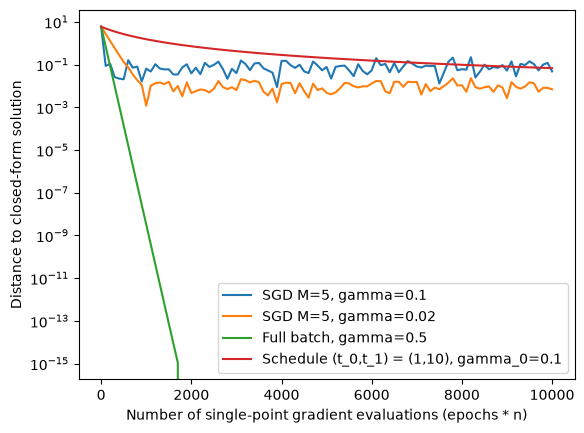

Schedule on degree-2 data:
  t0, t1 = (1.0, 10.0): gamma_0 = 0.10, gamma after 100 epochs = 0.0005, distance after 10 / 100 epochs 2.2e-02 / 4.7e-04
Schedule on degree-5 data:
  t0, t1 = (1.0, 10.0): gamma_0 = 0.10, gamma after 100 epochs = 0.0005, distance after 10 / 100 epochs 3.6e+00 / 3.0e+00
  t0, t1 = (5.0, 50.0): gamma_0 = 0.10, gamma after 100 epochs = 0.0024, distance after 10 / 100 epochs 2.4e+00 / 1.1e+00
  t0, t1 = (20.0, 200.0): gamma_0 = 0.10, gamma after 100 epochs = 0.0091, distance after 10 / 100 epochs 1.5e+00 / 2.5e-01
Answer: The schedule (1,10) works well for degree-2 data, but the distance gets too large for degree-5 data. Other schedule that has the same initial gamma is (5,50) and (20,200)
  M =   1: distance after 10 / 100 epochs 2.1e+10 / 8.9e+96
  M =   5: distance after 10 / 100 epochs 9.2e-01 / 1.3e-01
  M =  20: distance after 10 / 100 epochs 2.9e+00 / 2.1e-01
  M = 100: distance after 10 / 100 epochs 4.0e+00 / 2.0e+00
  largest single-point Hessian eigenv

In [7]:
# Your code for exercise 4 here

#4a)
#fixed point: theta = (0,3)
theta = np.array([0.0, 3.0])
g_full = gradient(theta, X2, y2)
print("full gradient:", g_full)

n = len(y2)
theta_cf = closed_form(X2, y2)

rng = np.random.default_rng(2026)
for M in (1, 5, 25,50):
    gs = np.array([gradient(theta, X2[b], y2[b]) for _ in range(40) for b in make_batches(n, M, rng)])
    print(f"M = {M:2d}: mean {np.round(gs.mean(axis=0), 3)}, spread {np.std(gs, axis=0).mean():.3f}")

    stddiff = np.std(gs, axis=0).mean() / np.std(gs_prev, axis=0).mean() if 'gs_prev' in locals() else None
    print("The spread falls with:", f"{stddiff:.3f} and 1/{np.sqrt(M):.3f}={1/np.sqrt(M):.3f}" if stddiff is not None else "N/A")
    if M == 1: gs_prev = gs


print("Answer: The mean does not change, but the spread decreases with increasing batch size. The mean is close to the full gradient. " \
"The spread falls as 1/sqrt(M), which means the tradeoff is that larger batch sizes give more accurate gradients, but they also require more computation. " \
"One therefore has to choose between accuracy and computational cost, and this is often a compromise.")

#4b)

for gamma in (0.1, 0.02):
    hist = sgd(X2, y2, n_epochs=100, batch_size=5, gamma=gamma) #batch_size M = 5
    d = np.linalg.norm(hist - theta_cf, axis=1)
    print(f"M = 5, gamma = {gamma}: distance after 1 / 10 / 100 epochs {d[1]:.1e} / {d[10]:.1e} / {d[100]:.1e}, "
          f"min over the last 50 epochs {d[50:].min():.1e}")

    plt.semilogy(np.arange(len(d)) * len(y2), d, label=f"SGD M=5, gamma={gamma}")

#Full batch GD
hist = sgd(X2, y2, n_epochs=100, batch_size=len(y2), gamma=0.5) #batch_size M = n
d = np.linalg.norm(hist - theta_cf, axis=1)
plt.semilogy(np.arange(len(d)) * len(y2), d, label=f"Full batch, gamma=0.5")
plt.xlabel("Number of single-point gradient evaluations (epochs * n)")
plt.ylabel("Distance to closed-form solution")

print("Answer: The full batch is ahead early, while SGD with gamma=0.02 is ahead late. SGD with a constant learning rate does converge, " \
"but it has a 'plateau' that is larger for larger gamma.")


#4c)
#initial learning rate is 0.1: each sched[0] / sched[1] = 0.1
hist = sgd(X2, y2, n_epochs=100, batch_size=len(y2), gamma=0.5,schedule=(1.0, 10.0)) #batch_size M = n
d = np.linalg.norm(hist - theta_cf, axis=1)
plt.semilogy(np.arange(len(d)) * len(y2), d, label=f"Schedule (t_0,t_1) = (1,10), gamma_0=0.1")
plt.legend()
plt.show()

sched = (1.0, 10.0)
hist = sgd(X2, y2, n_epochs=100, batch_size=5, schedule=sched)
d = np.linalg.norm(hist - theta_cf, axis=1)
print("Schedule on degree-2 data:")
print(f"  t0, t1 = {sched}: gamma_0 = {sched[0] / sched[1]:.2f}, gamma after 100 epochs = {step_length(100 * len(y2) // 5, *sched):.4f}, "
        f"distance after 10 / 100 epochs {d[10]:.1e} / {d[100]:.1e}")

#Degree-5 data:

print("Schedule on degree-5 data:")
theta_cf = closed_form(X5, y5)
#running same schedule
for sched in ((1.0, 10.0), (5.0, 50.0), (20.0, 200.0)):
    hist = sgd(X5, y5, n_epochs=100, batch_size=5, schedule=sched)
    d = np.linalg.norm(hist - theta_cf, axis=1)
    print(f"  t0, t1 = {sched}: gamma_0 = {sched[0] / sched[1]:.2f}, gamma after 100 epochs = {step_length(100 * len(y5) // 5, *sched):.4f}, "
            f"distance after 10 / 100 epochs {d[10]:.1e} / {d[100]:.1e}")

print("Answer: The schedule (1,10) works well for degree-2 data, but the distance gets too large for degree-5 data. Other schedule that has the same initial gamma is (5,50) and (20,200)")

### 4d)

for M in (1, 5, 20, 100):
    hist = sgd(X5, y5, n_epochs=100, batch_size=M, gamma=0.1)
    d = np.linalg.norm(hist - theta_cf, axis=1)
    print(f"  M = {M:3d}: distance after 10 / 100 epochs {d[10]:.1e} / {d[100]:.1e}")
xmax = np.max(np.linalg.norm(X5, axis=1))
print(f"  largest single-point Hessian eigenvalue 2|x_i|^2 = {2 * xmax**2:.1f}, so gamma must be below {2 / (2 * xmax**2):.3f} for M = 1")
print("Answer: The M=1 run diverges, because the largest single-point Hessian eigenvalue is 85.7 -> gamma must be below 0.0233. The gamma we used (0.1) is therefore too large for M=1.")

### 4e)

#Combine SGD with Adam on the degree-5 data ($M = 5$, $\gamma \in \{0.01, 0.05\}$, 100 epochs) and compare with plain SGD and with momentum. Which combination
#comes closest to the closed-form solution, and which one fails? This is the setting of Project 1, part h).

for method, gamma in (("plain", 0.1), ("momentum", 0.05), ("adam", 0.01), ("adam", 0.05)):
    hist = sgd(X5, y5, n_epochs=100, batch_size=5, gamma=gamma, method=method)
    d = np.linalg.norm(hist - theta_cf, axis=1)
    print(f"{method:8s} gamma = {gamma}: distance after 10 / 100 epochs {d[10]:.1e} / {d[100]:.1e}")

print("Answer: The combination of Adam with gamma=0.05 comes closest to the closed-form solution, while momentum with gamma=0.05 fails to converge.")




## Exercise 5: the Runge function at degree 10 (Project 1, parts f and h)

Last week nothing converged on the Runge function $f(x) = 1/(1+25x^2)$ on
$[-1, 1]$ ($n = 100$, noise $0.1$) with a degree-10 polynomial:
$\kappa \approx 2 \times 10^6$. Use the Tuesday session's `runge_data` (the same
standardisation as above).

### 5a)

Run momentum and Adam with the full gradient for 30 000 iterations and plot
the excess cost $C(\boldsymbol{\theta}_k) - C(\hat{\boldsymbol{\theta}}_{\mathrm{OLS}})$
against the iteration. What accuracy do they reach, and does either of them
resolve the flat directions? Explain, with the rotated bowl of the Tuesday
session in mind, why a diagonal rescaling cannot fix a problem whose
ill-conditioning comes from strongly correlated columns.

### 5b)

Add Ridge with $\lambda \in \{10^{-3}, 10^{-2}\}$: what are the condition
numbers now, and how many iterations do momentum and Adam need to reach an
excess cost of $10^{-8}$? Compare the Ridge coefficients with the OLS ones and
discuss whether Ridge is "cheating" — what problem has it solved, and is that
the problem you wanted solved? (Part i) of Project 1 answers the last question
with cross-validation.)

### 5c)

Take one Newton step from $\boldsymbol{\theta}_0 = \boldsymbol{0}$ with the exact
Hessian $\frac{2}{n}\boldsymbol{X}^T\boldsymbol{X}$ — or, following week 37, with
`jax.hessian` of your cost — and compare with the closed form. What did Newton
use that none of the first-order methods had, and why can we not simply do
this for a neural network?

### 5d)

Finally, minibatches: run SGD with Adam ($M = 10$, a decaying schedule of
your choice, 500 epochs) on the degree-10 problem and compare the excess cost
per gradient evaluation with the full-gradient Adam run of 5a). Give a
critical assessment, in the spirit of part h) of Project 1: what has the noise
bought, and what has it cost?

lambda = 0.0    kappa = 1.99e+06: momentum to 1e-8: None, after 30000: 2.2e-03
lambda = 0.0    kappa = 1.99e+06: adam     to 1e-8: None, after 30000: 1.4e-03
lambda = 0.001  kappa = 4.98e+03: momentum to 1e-8: 13210, after 30000: 2.2e-14
lambda = 0.001  kappa = 4.98e+03: adam     to 1e-8: 12070, after 30000: 2.0e-14
lambda = 0.01   kappa = 5.00e+02: momentum to 1e-8: 1330, after 30000: 6.9e-18
lambda = 0.01   kappa = 5.00e+02: adam     to 1e-8: 2500, after 30000: 1.9e-15


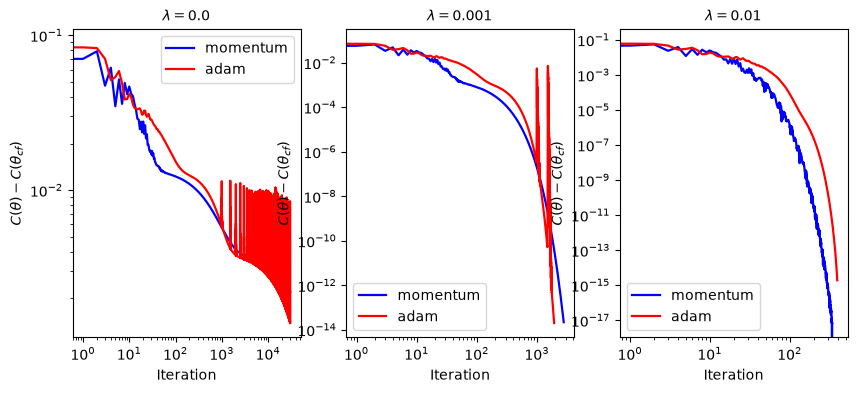

Answer: The Ridge makes the problem better conditioned, as both methods converge faster. TThe number of iterations to reach 1e-8 is smaller for Ridge than for OLS. The condition number decreases with increasing lambda. Ridge is not cheating. In addition to the gradient, it also uses a penalising for the features.
one Newton step: ||theta - closed form|| = 2.6e-09
OLS closed form : [-1.14559889e-01 -3.09075629e+00  4.32584127e-01  1.34078708e+01
 -6.37735763e-01 -2.65268432e+01  3.10990229e-01  2.43549480e+01
  6.32484268e-05 -8.40479698e+00]
Ridge 1e-3      : [-0.06071295 -1.08311798  0.13979829  1.33081575 -0.14043121 -0.07641436
 -0.05595847 -0.40018984  0.10297192 -0.00309303]
Ridge 1e-2      : [-0.02931024 -0.64140894  0.03370043  0.36142026 -0.00871682  0.22613745
 -0.00608585  0.00774866  0.01395914 -0.1633084 ]
Answer: The Newton step includes the Hessian matrix, which provides information about the shape as well, adding an extra dimension of information. We can not do the same 

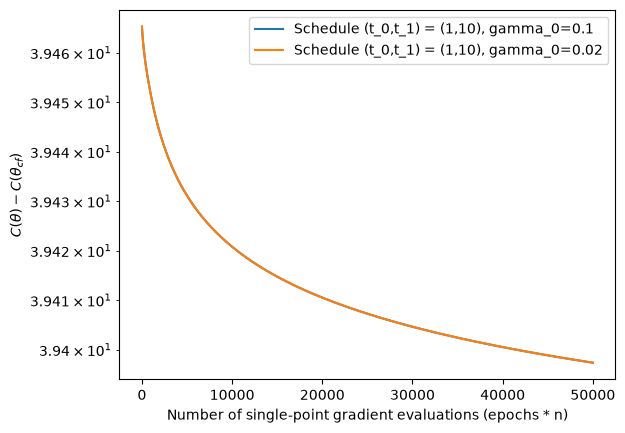

Answer: 


In [8]:
# Your code for exercise 5 here

def runge_data(n=100, degree=6, noise=0.1, seed=2026):
    """Runge function 1/(1+25x^2) on [-1,1], standardised polynomial features, centred y."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1.0, 1.0, n)
    y = 1.0 / (1.0 + 25.0 * x**2) + noise * rng.standard_normal(n)
    X = np.column_stack([x**k for k in range(1, degree + 1)])
    X_norm = (X - X.mean(axis=0)) / X.std(axis=0)
    return X_norm, y - y.mean()

#5a and b)

X10, y10 = runge_data(degree=10)
n10 = len(y10)
fig, axes = plt.subplots(1,3,figsize=(10, 4))
for lam, ax in zip((0.0, 1e-3, 1e-2), axes):
    theta_r = closed_form(X10, y10, lam)
    c_r = cost(theta_r, X10, y10, lam)
    eigs = hessian_eigs(X10, lam)
    for method, gamma, col in (("momentum", 0.9 * 2 / eigs.max(), "blue"), ("adam", 0.05, "red")):
        path, iters = optimise(lambda th: gradient(th, X10, y10, lam), np.zeros(10), method, gamma, num_iters=30000)
        e = np.array([cost(th, X10, y10, lam) - c_r for th in path[::1]])
        k = int(np.argmax(e < 1e-8)) * 10 if (e < 1e-8).any() else None
        print(f"lambda = {lam:<6} kappa = {eigs.max() / eigs.min():.2e}: {method:8s} to 1e-8: {k}, after 30000: {max(e[-1], 0):.1e}")

        ax.loglog(np.arange(iters+1),e,color=col,label=method, lw=1.6)

    ax.legend()
    ax.set_title(rf"$\lambda={lam}$", fontsize=10)
    ax.set_xlabel("Iteration")
    ax.set_ylabel(r"$C(\theta)-C(\theta_{cf})$")
plt.show()

print("Answer: The Ridge makes the problem better conditioned, as both methods converge faster. TThe number of iterations to reach 1e-8 is smaller for " \
"Ridge than for OLS. The condition number decreases with increasing lambda. Ridge is not cheating. In addition to the gradient, it also uses a penalising for the features.")

# 5c)
H10 = (2.0 / n10) * X10.T @ X10
theta_newton = np.zeros(10) - np.linalg.solve(H10, gradient(np.zeros(10), X10, y10))
print(f"one Newton step: ||theta - closed form|| = {np.linalg.norm(theta_newton - closed_form(X10, y10)):.1e}")
print("OLS closed form :", closed_form(X10, y10))
print("Ridge 1e-3      :", closed_form(X10, y10, 1e-3))
print("Ridge 1e-2      :", closed_form(X10, y10, 1e-2))


print("Answer: The Newton step includes the Hessian matrix, which provides information about the shape as well, adding an extra dimension of information. " \
"We can not do the same for neural networks because the Hessian is too large and expensive to compute, and it may not be positive definite.")


# 5d)

n = len(y10)
theta_cf = closed_form(X10, y10)
rng = np.random.default_rng(2026)

for gamma in (0.1, 0.02):
    hist = sgd(X10, y10, n_epochs=500, batch_size=10, gamma=gamma,schedule=(20.0, 200.0)) #batch_size M = 10
    d = np.linalg.norm(hist - theta_cf, axis=1)
    print(f"M = 10, gamma = {gamma}: distance after 1 / 10 / 100 epochs {d[1]:.1e} / {d[10]:.1e} / {d[100]:.1e}, "
          f"min over the last 50 epochs {d[50:].min():.1e}")

    plt.semilogy(np.arange(len(d)) * len(y10), d, label=f"Schedule (t_0,t_1) = (1,10), gamma_0={gamma}")

plt.xlabel("Number of single-point gradient evaluations (epochs * n)")
plt.ylabel(r"$C(\theta)-C(\theta_{cf})$")
plt.legend()
plt.show()

print("Answer: ")

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 1; the
right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| Adam converged for every learning rate from $10^{-3}$ to $1$ and plain gradient descent only in a narrow window. Does $\gamma$ not matter for Adam? | It matters for speed, not for stability: the adaptive step is at most $\gamma$ per coordinate (division by $\sqrt{\hat v}$), so $\gamma$ is a *length in parameter space* and cannot violate Eq. (4.20) — but the best $\gamma$ was still several times faster than the worst. |
| RMSProp at a constant $\gamma$ never reached $10^{-6}$ on a convex quadratic. Why? | Near the minimum $r \approx g^2$ and the step is $\approx \gamma\,\mathrm{sign}(g)$, a fixed length that cannot shrink: the iterate rattles at radius $\sim\gamma$. It needs a decaying $\gamma$ (Eq. 4.40), or the first moment — which is Adam. |
| AdaGrad was slower than plain gradient descent on the degree-6 Runge problem. Is it broken? | No: $\boldsymbol{r}_t$ never forgets, Eq. (4.42), so the effective learning rate decays like $1/\sqrt t$ whether or not the minimum is near. That is the wrong behaviour on a smooth convex problem and the right one for sparse features, which it was designed for. |
| Why does Adam divide its moments by $1 - \beta_i^t$? | Both averages start from zero, so $\mathbb{E}[v_t] = (1-\beta_2^t)\,\mathbb{E}[g^2]$, Eq. (4.53): at $t=1$ the raw second moment is a thousand times too small and the step would be $\sqrt{1000}/\sqrt{10}\approx 3$ times too long. Dividing by the known factor removes the bias exactly; for large $t$ the correction vanishes. |
| What does "adaptive" mean, in one sentence? | Each coordinate gets its own step $\gamma/\sqrt{v_j}$, with $v_j$ the recent mean square gradient as a proxy for the curvature $\lambda_j$: a diagonal, $\mathcal{O}(p)$ imitation of Newton's $\boldsymbol{H}^{-1/2}$ (Section 4.8). |
| Rotating the bowl by $45^\circ$ left plain gradient descent unchanged and made AdaGrad and RMSProp fail. Why? | Eq. (4.19) depends on the eigenvalues only, which a rotation preserves; the adaptive methods rescale *coordinates* and see only the diagonal of $\boldsymbol{H}$. A valley that is not axis-aligned — a correlated polynomial basis, for instance — has its curvature off the diagonal. |
| Every first-order method stalled at an excess cost of $10^{-3}$ on the degree-10 Runge problem, and one Newton step solved it. What did Newton have? | The full Hessian, off-diagonal entries included: $\kappa = 2\times10^6$ is invisible to it, Eq. (4.8). We cannot afford it for a network ($\mathcal{O}(p^3)$); every method from momentum to Adam is a cheaper approximation to it. |
| Book Table 4.1: no optimiser is best at the same $\gamma$ as any other. What does that mean for comparing methods? | A learning rate is not comparable across optimisers — plain descent multiplies the gradient by $\gamma$, the adaptive methods normalise it first. Compare methods at each one's *best* $\gamma$, found by a scan, never at one shared value. |
| Plain SGD with $M=5$ sat at a distance $5\times10^{-2}$ from the minimum for ninety epochs. Has it converged? | No, it has equilibrated: the minibatch gradient is an unbiased estimate with noise $\propto 1/\sqrt M$ (Section 2.5), and at constant $\gamma$ the iterate is a random walk in a cloud of radius $\propto\sqrt\gamma/\sqrt M$. A longer run does not help; a smaller $\gamma$, a larger $M$ or a decaying $\gamma_t$ does. |
| Full-batch gradient descent beat SGD per gradient evaluation on the degree-2 data. Is SGD overrated? | On a small benign problem the exact gradient is cheap and converges geometrically, Eq. (4.26). For $n = 10^6$ one full gradient costs $10^4$ minibatch steps: per unit of computation SGD is far ahead, and it never needs the whole data set in memory — which is why every framework is built on minibatches. |
| The schedule $(t_0,t_1)=(1,10)$ worked at degree 2 and froze at degree 5. Which condition did it break? | Robbins–Monro needs $\sum_t\gamma_t = \infty$; in a finite run $\gamma_t = t_0/(t+t_1)$ with a small $t_1$ decays so fast that the accumulated step cannot cross a $\kappa = 520$ valley. Keep $\gamma_0 = t_0/t_1$ and enlarge both, so the decay starts later. |
| SGD with $M=1$ diverged at a $\gamma$ below $2/\lambda_{\max}$ of the full Hessian. How? | A minibatch step sees the Hessian of the *minibatch* cost; for one point it is $2\boldsymbol{x}_i\boldsymbol{x}_i^T$ with eigenvalue $2\|\boldsymbol{x}_i\|^2$, far above the average. The full-batch bound is a bound on the average, not on every step. |
| When should I stop a stochastic run? | Not on the gradient: monitor the validation cost and stop when it rises while the training cost still falls (early stopping, Section 4.7.1) — a regularisation method as much as a termination rule. |


### Practicalities

Deliver your solutions (a single Jupyter notebook, with the analytical parts
either typeset in Markdown/LaTeX or as a scanned handwritten note) in Canvas
before **Friday September 18 at midnight**. Collaboration is encouraged — list
your collaborators.